# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.Fm Linear Regression Notebook
*By Mark Lambert - C00192497*

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 3rd November 2026*

*Start Date: 17th October 2026*

---

This notebook explores a linear regression question using Last.fm scrobbles merged with Spotify track features:

- Does the average release year of music I scrobble change from week to week?


Every scrobble is joined to its track's Spotify features, using the same cleaning functions as the collection notebook, with times converted to Dublin local time

```%pip install pandas scikit-learn matplotlib```

### Load and prepare the scrobble data

Load the raw scrobbles and the merged track features, clean the artist and track names so the two files can be joined, and keep only plays that matched a Spotify record. Dates are converted to Dublin time so weeks line up with my actual day

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# same cleaning functions used in the collection notebook, so the keys match exactly
def clean_text(s):
    s = s.str.replace(r'\s*[\(\[].*?[\)\]]', '', regex=True)
    s = s.str.replace(r'\s*-.*$', '', regex=True)
    s = s.str.replace(r'[^\w\s]', '', regex=True)
    return s.str.replace(r'\s+', ' ', regex=True).str.strip()

def clean_artist(s):
    s = s.str.lower().str.split('/').str[0].str.split('&').str[0]
    return s.str.replace(r'[^\w\s]', '', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']
tags = ['release_year', 'popularity', 'artist_popularity', 'explicit']

plays = pd.read_csv('datasets/scrobbles.csv')
scrobbles = pd.read_csv('datasets/scrobbled_merged_with_hugging_face.csv')

# Dublin time
local = pd.to_datetime(plays['date']).dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
plays['local_time'] = local.dt.tz_localize(None)
plays['local_date'] = plays['local_time'].dt.normalize()

plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

# one row per unique track with its Spotify features
scrobbles_unique = scrobbles.drop_duplicates(['clean_artist', 'clean_track']).copy()

# every play that could be matched to Spotify features
plays_feat = plays.merge(scrobbles_unique[['clean_artist', 'clean_track'] + audio + tags],
                         on=['clean_artist', 'clean_track'], how='inner')

print(f"All scrobbles:                  {len(plays):,}")
print(f"Scrobbles with Spotify features: {len(plays_feat):,}  ({len(plays_feat) / len(plays):.1%} of plays)")
print(f"Unique tracks with features:     {len(scrobbles_unique):,}  (rows in the merged file: {len(scrobbles):,})")
print(f"Listening window: {plays['local_date'].min().date()} to {plays['local_date'].max().date()}")

All scrobbles:                  17,999
Scrobbles with Spotify features: 14,629  (81.3% of plays)
Unique tracks with features:     1,838  (rows in the merged file: 1,838)
Listening window: 2025-11-18 to 2026-10-14


### Fit a linear trend to weekly averages

This cell groups scrobbles by week and calculates the average release year of tracks played each week. It uses week as the predictor and average release year as the response, then fits a straight line.

The slope describes weekly change, R-squared describes how much of the variation the line accounts for. The plot shows the observed averages and fitted trend

- Weeks with very few matched plays give weird averages, so weeks below `min_plays` are dropped 
- Time is measured in **years**


Weeks before filtering: 48;  after dropping weeks with < 25 plays: 48
Model slope:     +1.76 release years per year
Model intercept: 2003.3
R-squared:       0.024
Total weeks analyzed: 48


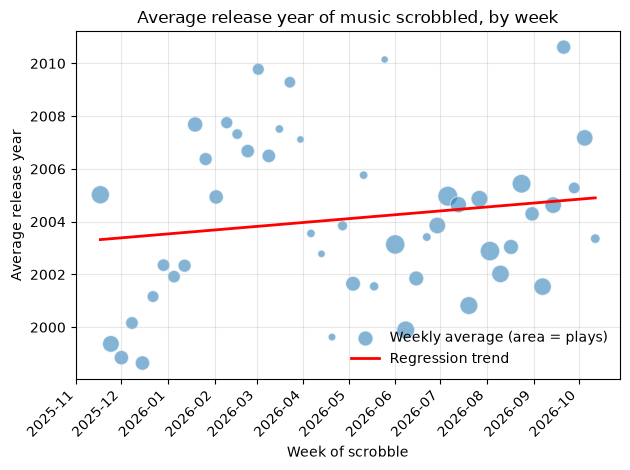

In [3]:
plays_feat['week'] = plays_feat['local_time'].dt.to_period('W').dt.start_time

weekly_trend = plays_feat.groupby('week').agg(
    avg_release_year=('release_year', 'mean'),
    scrobble_count=('release_year', 'size'),
).reset_index()

MIN_PLAYS = 25
print(f"Weeks before filtering: {len(weekly_trend)};  after dropping weeks with < {MIN_PLAYS} plays: {(weekly_trend.scrobble_count >= MIN_PLAYS).sum()}")
weekly_trend = weekly_trend[weekly_trend['scrobble_count'] >= MIN_PLAYS].reset_index(drop=True)
weekly_trend['years_since_start'] = (weekly_trend['week'] - weekly_trend['week'].min()).dt.days / 365.25

X = weekly_trend[['years_since_start']]
y = weekly_trend['avg_release_year']

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
# fit the estimator, then inspect the fitted parameters (trailing underscore)
model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(f"Model slope:     {model.coef_[0]:+.2f} release years per year")
print(f"Model intercept: {model.intercept_:.1f}")
print(f"R-squared:       {model.score(X, y):.3f}")
print(f"Total weeks analyzed: {len(weekly_trend)}")

# area of each dot is proportional to the number of plays behind that week
fig, ax = plt.subplots()
ax.scatter(weekly_trend['week'], y, s=weekly_trend['scrobble_count'] / 3,
           color='tab:blue', alpha=0.55, edgecolor='white', linewidth=0.8,
           label='Weekly average (area = plays)')
ax.plot(weekly_trend['week'], model.predict(X), color='red', lw=2, label='Regression trend')
ax.set(title='Average release year of music scrobbled, by week',
       xlabel='Week of scrobble', ylabel='Average release year')
ax.legend(frameon=False)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
scrobbles = scrobbles.sort_values('date')
scrobbles['date'] = pd.to_datetime(scrobbles['date'])

# create a week col starts on Mondays
plays_feat['week'] = plays_feat['local_time'].dt.to_period('W').dt.start_time

# calculate the average release year
weekly_trend = plays_feat.groupby('week').agg(
    avg_release_year=('release_year', 'mean'),
    scrobble_count=('release_year', 'size'),
).reset_index()

min_plays = 25
weekly_trend = weekly_trend[weekly_trend['scrobble_count'] >= min_plays].reset_index(drop=True)
weekly_trend['years_since_start'] = (weekly_trend['week'] - weekly_trend['week'].min()).dt.days / 365.25

X = weekly_trend[['years_since_start']]
y = weekly_trend['avg_release_year']

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
# fit the estimator, then use predict() and score() for model evaluation
model = LinearRegression()
model.fit(X, y)

print(f"Slope (Years changed per week): {model.coef_[0]:.3f}")
print(f"Model intercept: {model.intercept_:.1f}")
print(f"R-squared: {model.score(X, y):.4f}")
print(f"Total weeks analyzed: {len(weekly_trend)}")

plt.scatter(weekly_trend['week'], y, label='Actual Weekly Average')

plt.plot(weekly_trend['week'], model.predict(X), color='red', label='Regression Trend')
plt.xticks(rotation=45)
plt.title('Average Release Year of Music Scrobbled (By Week)')
plt.xlabel('Week of Scrobble')
plt.ylabel('Average Release Year')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'MIN_PLAYS' is not defined

### Express the trend as change per year

The earlier slope is measured per week.

This cell measures time in weeks since the first observation, refits the same model, and multiplies the slope by 52


In [3]:
weekly_trend = weekly_trend.sort_values("week").reset_index(drop=True)
weekly_trend["weeks_since_start"] = (
    (weekly_trend["week"] - weekly_trend["week"].min()).dt.days / 7
)

X = weekly_trend[["weeks_since_start"]]
y = weekly_trend["avg_release_year"]

# Adapted from PythonDataScienceHandbook/notebooks/05.06-Linear-Regression.ipynb:
# refit the estimator on the interpretable time feature and report its slope
model.fit(X, y)
print(f"Change per year: {model.coef_[0] * 52:.2f} release years")

Change per year: 13.62 release years


### Add weekly scrobble counts

This cell rebuilds the weekly summary with both average release year and the number of scrobbles in each week. The count is used to show how much listening supports each weekly average in the next plot


In [6]:
weekly_trend = scrobbles.groupby("week").agg(
    avg_release_year=("release_year", "mean"),
    scrobble_count=("release_year", "count")
).reset_index()

min_plays = 25
weekly_trend = weekly_trend[weekly_trend['scrobble_count'] >= min_plays].reset_index(drop=True)
weekly_trend['years_since_start'] = (weekly_trend['week'] - weekly_trend['week'].min()).dt.days / 365.25

X = weekly_trend[['years_since_start']]
y = weekly_trend['avg_release_year']

# Fit the estimator, then inspect the fitted parameters (trailing underscore), as in the Handbook
model = LinearRegression(fit_intercept=True)
model.fit(X, y)

print(f"Model slope:     {model.coef_[0]:+.2f} release years per year")
print(f"Model intercept: {model.intercept_:.1f}")
print(f"R-squared:       {model.score(X, y):.3f}")

Model slope:     +12.23 release years per year
Model intercept: 1994.5
R-squared:       0.127


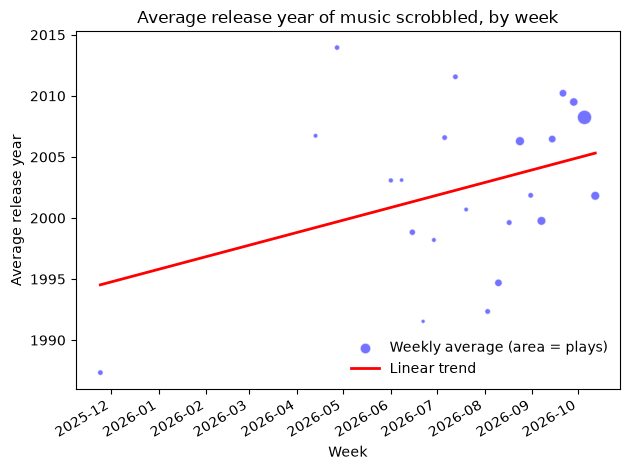

In [9]:
fig, ax = plt.subplots()
ax.scatter(weekly_trend['week'], y, s=weekly_trend['scrobble_count'] / 3, color='blue', alpha=0.55,
           edgecolor='white', linewidth=0.8, label='Weekly average (area = plays)')
ax.plot(weekly_trend['week'], model.predict(X), color='red', lw=2, label='Linear trend')
ax.set(title='Average release year of music scrobbled, by week',
       xlabel='Week', ylabel='Average release year')
ax.legend(frameon=False)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout(); plt.show()